# Choosing the null set, and knowing what the choice is worth

`fdaSP.SBC` fits an estimator whose whole purpose is a coefficient function that is exactly
zero on part of its domain. Which part depends on the penalty, and the penalty is chosen by
cross-validation, which minimises prediction error. This repository has now measured the gap
between those two targets three times, and it is not marginal:

- `notebooks/LocSpaFLR_f2s.ipynb` -- the cross-validated fit returns a null set of length zero
  on all three of the paper's own designs;
- `notebooks/basis_and_coef_comp.ipynb` -- the same on all nine designs there, on every
  replication;
- `notebooks/tecator_application.ipynb` -- the null region the paper reports sits at a penalty
  7.75 standard errors above the cross-validated minimum, and the authors' own `f2sSP_cv` does
  not reach it either.

An exact zero is worth more for describing a coefficient function than for predicting a
response, so the prediction optimum sits at a smaller penalty than the support optimum. The
estimator can represent a null set; the rule that selects it cannot find one.

`notebooks/HH_vs_SBC.ipynb` states the other half of the problem. What the truncation model has
and the penalty does not is "an explicit endpoint estimate with a sampling distribution, rather
than a null set read off whichever basis groups the penalty switched off". This notebook
supplies that missing distribution theory without assuming one, and the object it returns is
not a boundary but a **three-way partition** of the domain -- informative, null, and neither --
with an error bound on each of the first two.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fts_research.core import paths, style
from fts_research.core.bases import bspline_basis
from fts_research.fdaSP import SBC, SBC_sim, intraday as itd
from fts_research.region import bounds, criteria, stability, study

style.use(plt)
pd.set_option("display.width", 170)

INFORMATIVE, NULL_C = style.CATEGORICAL[0], style.CATEGORICAL[2]
UNDECIDED = style.CONTROL
N_BASIS, ORDER = 15, 4

## 1. The variables of the selection problem are knot intervals

A B-spline of order $d$ covers every point of the domain with exactly $d$ basis functions, so
the fitted function is identically zero on knot interval $b$ precisely when coefficients
$b, \dots, b+d-1$ all vanish -- and that set of coefficients is exactly group $b$ of the
overlap penalty. "Group $b$ is selected" and "the estimate is not identically zero on knot
interval $b$" are therefore the *same event*, which is what turns a selection probability from
a statement about a basis into a statement about the domain.

Everything below rests on that correspondence, so `tests/test_region.py` checks it against the
basis itself rather than taking it on trust.

switching off group 5 zeroes the function exactly on [0.417, 0.500]; knot interval 5 is [0.417, 0.500]


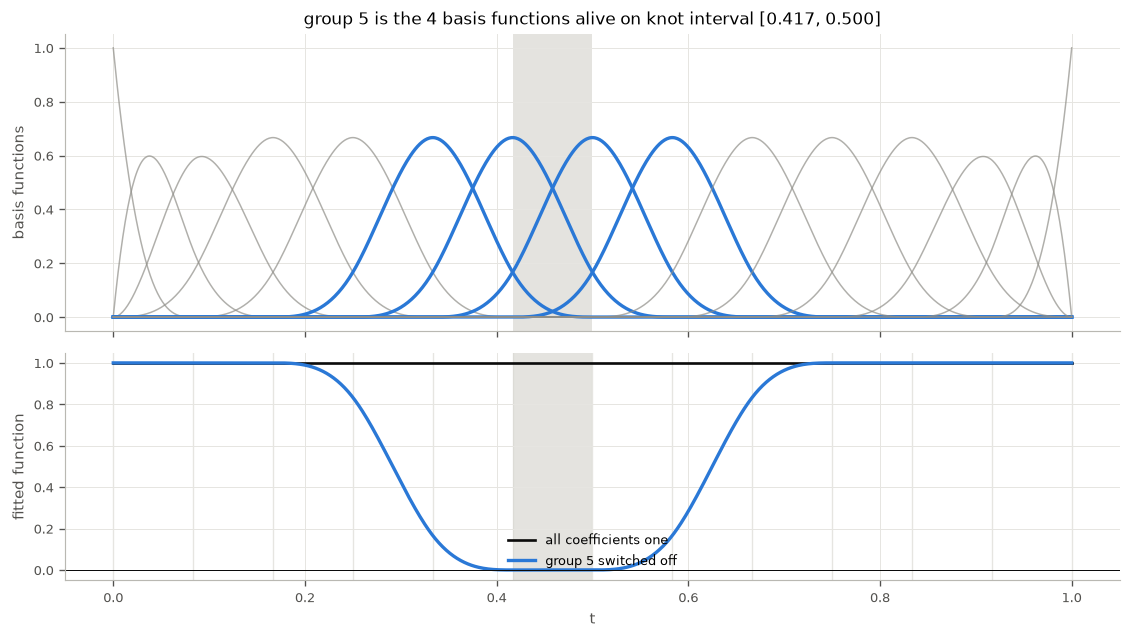

In [2]:
grid = np.linspace(0, 1, 801)
Phi = bspline_basis(grid, n_basis=N_BASIS, order=ORDER)
edges = stability.knot_edges(N_BASIS, ORDER)
_, groups = SBC.pen_matrices(N_BASIS, order=ORDER)
show = 5                                              # one group, highlighted

fig, axes = plt.subplots(2, 1, figsize=(9.5, 5.4), sharex=True,
                         gridspec_kw={"height_ratios": [1.3, 1]})
for j in range(N_BASIS):
    inside = j in groups[show]
    axes[0].plot(grid, Phi[:, j], lw=2.0 if inside else 0.9,
                 color=INFORMATIVE if inside else style.CONTROL,
                 alpha=1.0 if inside else 0.7)
axes[0].axvspan(edges[show], edges[show + 1], color=style.BAND, alpha=0.7, lw=0)
axes[0].set_ylabel("basis functions")
axes[0].set_title(f"group {show} is the {ORDER} basis functions alive on knot interval "
                  f"[{edges[show]:.3f}, {edges[show + 1]:.3f}]")

psi = np.ones(N_BASIS)
axes[1].plot(grid, Phi @ psi, color=style.INK, lw=1.6, label="all coefficients one")
psi_off = psi.copy(); psi_off[groups[show]] = 0.0
axes[1].plot(grid, Phi @ psi_off, color=INFORMATIVE, lw=2.0,
             label=f"group {show} switched off")
axes[1].axvspan(edges[show], edges[show + 1], color=style.BAND, alpha=0.7, lw=0)
axes[1].axhline(0, color=style.INK, lw=0.6)
for e in edges:
    axes[1].axvline(e, color=style.GRID, lw=0.8, zorder=0)
axes[1].set_xlabel("t"); axes[1].set_ylabel("fitted function")
axes[1].legend(frameon=False, loc="lower center")
fig.tight_layout()

zeroed = np.abs(Phi @ psi_off) < 1e-12
print(f"switching off group {show} zeroes the function exactly on "
      f"[{grid[zeroed].min():.3f}, {grid[zeroed].max():.3f}]; "
      f"knot interval {show} is [{edges[show]:.3f}, {edges[show + 1]:.3f}]")

## 2. What a threshold on the selection proportions is worth

Complementary pairs stability selection refits on disjoint halves of the data and records how often
each group survives. Shah and Samworth's [[43]](../docs/references.md#ref-shah-samworth-2013)
Theorem 1 bounds the expected number of rarely-selected groups that a threshold $\tau$ keeps, and
does so under no assumption about the model, the estimator, or the number of pairs. `region.bounds`
implements all three of their bounds: the worst case, which assumes nothing; the unimodal one; and
equation (8), which is the tightest and needs $D(\eta, t, B, r)$, the largest tail an $r$-concave
distribution on the lattice with mean at most $\eta$ can have.

$D$ has no closed form. The paper's Section A.4 computes it by parametrising the extremal mass
functions by their support and one scale, and states the algorithm for a *decreasing*
maximiser, which holds when $t > 2\eta$ and which the paper sets the other case aside as "less
important for our application". It is not unimportant for a functional penalty, whose groups
are few and often selected, so `r_concave_tail` falls back on Markov's inequality outside that
range -- an error there would make the reported control too *small*, which is the one direction
an error control may not fail in.

worst case at tau = 0.6: 12.500 (Meinshausen-Buhlmann's q^2 / (p (2 tau - 1)) = 12.500)
r-concave at the same threshold:  2.605


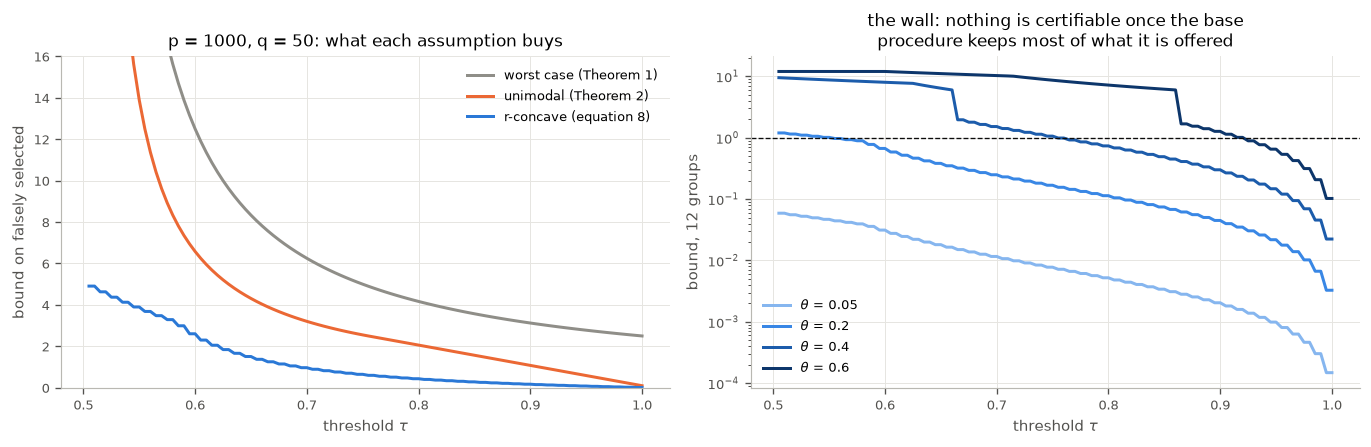

In [3]:
p, q = 1000, 50
theta = q / p
taus = np.linspace(0.505, 1.0, 100)
curves = {
    "worst case (Theorem 1)": [bounds.false_selection_bound(theta, t, 50, p, q,
                                                            "worst-case") for t in taus],
    "unimodal (Theorem 2)": [bounds.false_selection_bound(theta, t, 50, p, q,
                                                          "unimodal") for t in taus],
    "r-concave (equation 8)": [bounds.false_selection_bound(theta, t, 50, p, q) for t in taus],
}

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
for (label, values), colour in zip(curves.items(),
                                   (style.CONTROL, style.CATEGORICAL[1], INFORMATIVE)):
    axes[0].plot(taus, values, lw=1.8, color=colour, label=label)
axes[0].set_ylim(0, 16); axes[0].set_xlabel(r"threshold $\tau$")
axes[0].set_ylabel("bound on falsely selected")
axes[0].set_title(f"p = {p}, q = {q}: what each assumption buys")
axes[0].legend(frameon=False)

for th, colour in zip((0.05, 0.2, 0.4, 0.6), style.ordinal(4)):
    axes[1].plot(taus, [bounds.false_selection_bound(th, t, 50, 12, th * 12) for t in taus],
                 lw=1.8, color=colour, label=rf"$\theta$ = {th}")
axes[1].axhline(1.0, color=style.INK, lw=0.8, ls="--")
axes[1].set_yscale("log"); axes[1].set_xlabel(r"threshold $\tau$")
axes[1].set_ylabel("bound, 12 groups")
axes[1].set_title("the wall: nothing is certifiable once the base\n"
                  "procedure keeps most of what it is offered")
axes[1].legend(frameon=False)
fig.tight_layout()

print(f"worst case at tau = 0.6: {curves['worst case (Theorem 1)'][19]:.3f} "
      f"(Meinshausen-Buhlmann's q^2 / (p (2 tau - 1)) = "
      f"{q ** 2 / (p * (2 * taus[19] - 1)):.3f})")
print(f"r-concave at the same threshold:  {curves['r-concave (equation 8)'][19]:.3f}")

The right-hand panel is the reason the base procedure here is indexed by **how many groups it
keeps** rather than by the penalty. The bound is driven by $\theta = q/n_{\text{groups}}$
through quantities no larger than Markov's $\theta/\tau$, so once $\theta$ passes a half no
threshold can certify anything: a procedure that keeps most of what it is offered keeps the
noise too. A functional penalty has few groups and a coefficient function that is usually
non-zero over much of the domain, so a fixed penalty anywhere near the cross-validated one puts
$\theta$ well above a half. Lowering the penalty on each subsample until $q$ groups have
entered -- which the path gives for nothing -- makes $\theta$ a choice rather than an accident.

The two halves of the claim then want opposite sizes. An inclusion is certified where the
procedure is sparse; an exclusion is certified where it is dense, by applying the same theorem
to the **complementary** procedure, since discarding a group is a selection like any other and
its selection probabilities are $1 - p_b$. Theorem 1(ii) says the same thing directly but
scales by a quantity for which the number of candidates is vacuous rather than conservative;
read through the complement, the rigorous scaling applies to both halves.

## 3. One dataset, end to end

`psi2` is the paper's rescaled Epanechnikov kernel, zero outside $[0.25, 0.75]$. Every rule
below reads the same penalty path on the same data and differs in nothing else.

In [4]:
X, y, sim_grid, beta_true = SBC_sim.simulate(SBC_sim.psi2, n=100, m=100, snr=4.0, rng=1)
true_null = (sim_grid < 0.25) | (sim_grid > 0.75)

curves = stability.selection_curves(X, y, sim_grid, n_basis=N_BASIS, order=ORDER,
                                    n_pairs=50, n_lambda=40, rng=0)
chosen = stability.select(curves, pfer=1.0, pner=1.0)

print(f"base procedure keeping {chosen['size_in']} group(s): theta = "
      f"{chosen['theta_in']:.3f}, threshold {chosen['tau_hi']:.3f}, "
      f"expected false inclusions <= {chosen['bound_false']:.3f}")
print(f"base procedure keeping {chosen['size_out']} group(s): theta = "
      f"{chosen['theta_out']:.3f}, threshold {chosen['tau_lo']:.3f}, "
      f"expected false exclusions <= {chosen['bound_missed']:.3f}")
print()
print("  certified informative:", [(round(a, 3), round(b, 3))
                                   for a, b in stability.regions(chosen["informative"],
                                                                 curves)])
print("  certified null       :", [(round(a, 3), round(b, 3))
                                   for a, b in stability.regions(chosen["null"], curves)])
print("  undecided            :", [(round(a, 3), round(b, 3))
                                   for a, b in stability.regions(chosen["undecided"],
                                                                 curves)])
print("  the truth is informative on [0.25, 0.75] and null outside it")

base procedure keeping 1 group(s): theta = 0.723, threshold nan, expected false inclusions <= inf
base procedure keeping 8 group(s): theta = 0.724, threshold 0.360, expected false exclusions <= 0.931

  certified informative: []
  certified null       : [(0.0, 0.167), (0.833, 1.0)]
  undecided            : [(0.167, 0.833)]
  the truth is informative on [0.25, 0.75] and null outside it


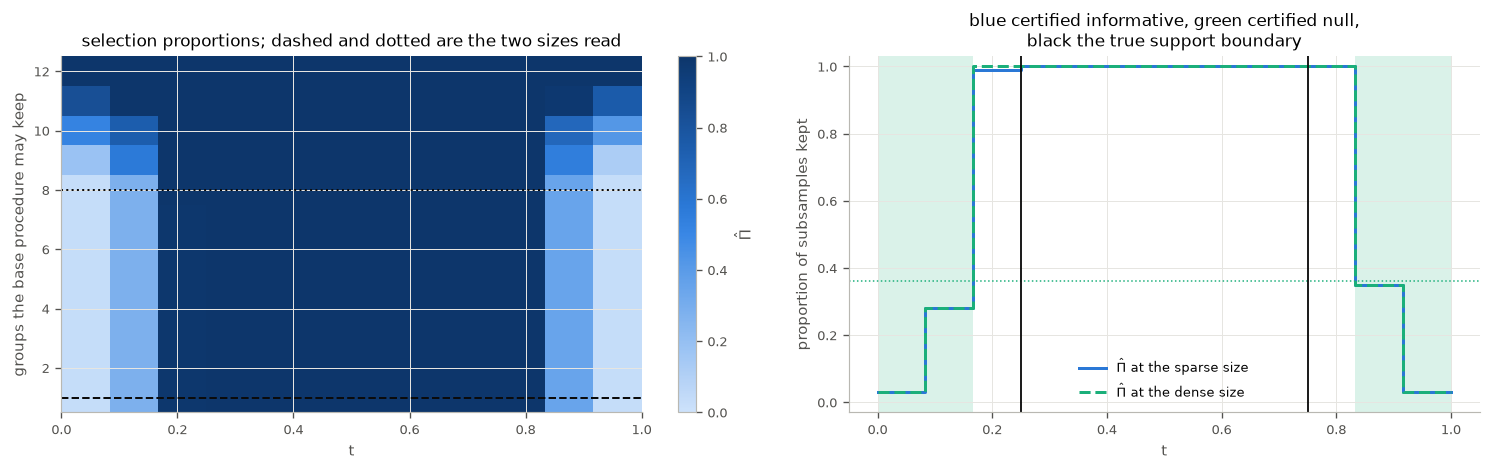

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0),
                         gridspec_kw={"width_ratios": [1.15, 1]})

im = axes[0].imshow(curves["pi"], aspect="auto", origin="lower", cmap=style.SEQUENTIAL,
                    vmin=0, vmax=1,
                    extent=[curves["edges"][0], curves["edges"][-1],
                            0.5, curves["n_groups"] + 0.5])
axes[0].axhline(chosen["size_in"], color=style.INK, lw=1.2, ls="--")
axes[0].axhline(chosen["size_out"], color=style.INK, lw=1.2, ls=":")
axes[0].set_xlabel("t"); axes[0].set_ylabel("groups the base procedure may keep")
axes[0].set_title("selection proportions; dashed and dotted are the two sizes read")
fig.colorbar(im, ax=axes[0], label=r"$\hat\Pi$")

mid = 0.5 * (curves["edges"][:-1] + curves["edges"][1:])
axes[1].step(np.r_[curves["edges"][0], mid, curves["edges"][-1]],
             np.r_[chosen["pi_in"][0], chosen["pi_in"], chosen["pi_in"][-1]],
             where="mid", color=INFORMATIVE, lw=1.8, label=r"$\hat\Pi$ at the sparse size")
axes[1].step(np.r_[curves["edges"][0], mid, curves["edges"][-1]],
             np.r_[chosen["pi_out"][0], chosen["pi_out"], chosen["pi_out"][-1]],
             where="mid", color=NULL_C, lw=1.8, ls="--",
             label=r"$\hat\Pi$ at the dense size")
axes[1].axhline(chosen["tau_hi"], color=INFORMATIVE, lw=0.9, ls=":")
axes[1].axhline(chosen["tau_lo"], color=NULL_C, lw=0.9, ls=":")
for lo, hi in stability.regions(chosen["informative"], curves):
    axes[1].axvspan(lo, hi, color=INFORMATIVE, alpha=0.13, lw=0)
for lo, hi in stability.regions(chosen["null"], curves):
    axes[1].axvspan(lo, hi, color=NULL_C, alpha=0.16, lw=0)
for edge in (0.25, 0.75):
    axes[1].axvline(edge, color=style.INK, lw=1.1)
axes[1].set_ylim(-0.03, 1.03); axes[1].set_xlabel("t")
axes[1].set_ylabel("proportion of subsamples kept")
axes[1].set_title("blue certified informative, green certified null,\n"
                  "black the true support boundary")
axes[1].legend(frameon=False, loc="lower center", fontsize=8)
fig.tight_layout()

In [6]:
# The same path, read by the rules that target prediction instead.
path = SBC.fit_path(X, y, sim_grid, n_basis=N_BASIS, order=ORDER, n_lambda=40)
cv = SBC.cv_fit(X, y, sim_grid, lambdas=path["lambdas"], n_basis=N_BASIS, order=ORDER,
                n_folds=5, rng=1)
best = int(np.argmin(cv["cv_mean"]))
one_se = int(np.argmax(cv["cv_mean"] <= cv["cv_mean"][best] + cv["cv_se"][best]))
ebic = criteria.ebic(path, y)

rows = []
for label, null_hat in (("cross-validation", ~path["supports"][best]),
                        ("cross-validation, 1 SE", ~path["supports"][one_se]),
                        ("EBIC", ~path["supports"][ebic["step"]]),
                        ("stability, certified null", chosen["null_grid"])):
    scores = criteria.support_error(null_hat, true_null, sim_grid)
    rows.append({"rule": label, **{k: scores[k] for k in
                                   ("null_len", "false_null", "missed_null", "jaccard")}})
comparison = pd.DataFrame(rows).set_index("rule")
comparison.loc["stability, certified null", "undecided"] = criteria.measure(
    chosen["undecided_grid"], sim_grid)
print("null set, as measures on a domain of length 1 (the truth has length 0.5)\n")
print(comparison.round(4).to_string())

null set, as measures on a domain of length 1 (the truth has length 0.5)

                           null_len  false_null  missed_null  jaccard  undecided
rule                                                                            
cross-validation             0.1667         0.0       0.3283   0.3367        NaN
cross-validation, 1 SE       0.3333         0.0       0.1616   0.6735        NaN
EBIC                         0.3333         0.0       0.1616   0.6735        NaN
stability, certified null    0.3333         0.0       0.1616   0.6735     0.6667


Every rule finds part of the true null set on this draw and none of them asserts anything
false, which is what the design deserves: `psi2`'s null set is half the domain and its support
is large in the middle. What separates them is on the right of the table. Only one of them says
which part of the domain it could not decide, and only one carries a number saying what the
claim is worth.

The column that matters is `false_null`: domain called null where the coefficient function is
not zero. That is the assertion a locally sparse estimate exists to make and the one it can get
wrong, and one draw cannot settle how often it does -- which is what the next section is for.

## 4. Four rules over four designs

`region.study` runs all of them over the three designs of Stefanucci, Bernardi and Canale --
the third of which has no null region at all and is the control against inventing one -- and a
fourth whose null set is $[0, 0.7)$, which is Hall and Hooker's own right-anchored
configuration and the shape the overnight-jump application has. The cache is rebuilt by
`scripts/make_region_cache.py`.

In [7]:
frame = pd.read_csv(paths.cache_path("region_study.csv"))
table = study.summarise(frame)
print(f"{frame['seed'].nunique()} replications per design, n = {frame['n'].iloc[0]}, "
      f"snr = {frame['snr'].iloc[0]}\n")
print(table[["false_null", "missed_null", "null_len", "undecided", "false_null_rate",
             "ise_relaxed"]].round(4).to_string())

25 replications per design, n = 100, snr = 4.0

                           false_null  missed_null  null_len  undecided  false_null_rate  ise_relaxed
design rule                                                                                          
psi1   cv                      0.0000       0.4040    0.0000     0.0000             0.00       0.0796
       cv-1se                  0.0000       0.4040    0.0000     0.0000             0.00       0.0683
       ebic                    0.0000       0.4040    0.0000     0.0000             0.00       0.0683
       stability               0.0000       0.2323    0.1717     0.5000             0.20       0.0625
       stability-adaptive      0.0000       0.0707    0.3333     0.0000             0.20       0.0545
psi2   cv                      0.0000       0.4949    0.0000     0.0000             0.00       0.0225
       cv-1se                  0.0000       0.2424    0.2525     0.0000             0.00       0.0081
       ebic                    0.0

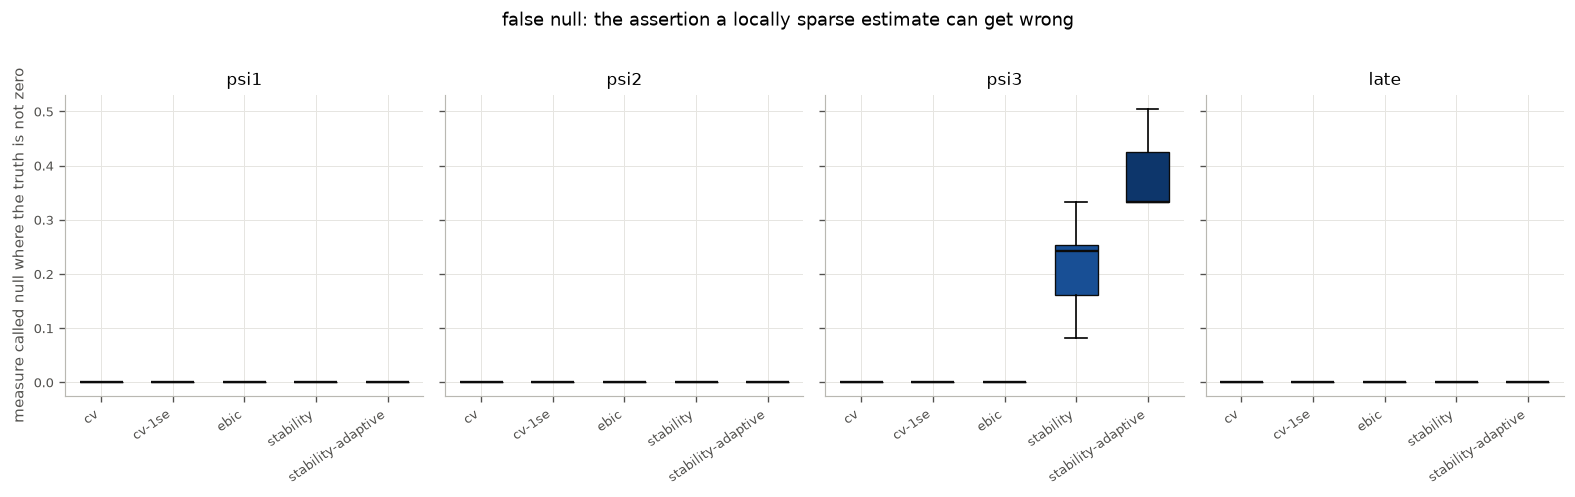

In [8]:
designs = list(dict.fromkeys(frame["design"]))
rules = [r for r in study.RULES if r in set(frame["rule"])]
fig, axes = plt.subplots(1, len(designs), figsize=(3.3 * len(designs), 4.0), sharey=True)
for ax, design in zip(np.atleast_1d(axes), designs):
    sub = frame[frame["design"] == design]
    data = [sub[sub["rule"] == r]["false_null"].to_numpy() for r in rules]
    parts = ax.boxplot(data, patch_artist=True, widths=0.6, showfliers=False)
    for patch, colour in zip(parts["boxes"], style.ordinal(len(rules))):
        patch.set_facecolor(colour); patch.set_edgecolor(style.INK); patch.set_linewidth(0.8)
    for whisker in parts["medians"]:
        whisker.set_color(style.INK); whisker.set_linewidth(1.4)
    ax.set_xticks(range(1, len(rules) + 1))
    ax.set_xticklabels(rules, rotation=35, ha="right", fontsize=8)
    ax.set_title(design)
np.atleast_1d(axes)[0].set_ylabel("measure called null where the truth is not zero")
fig.suptitle("false null: the assertion a locally sparse estimate can get wrong", y=1.02)
fig.tight_layout()

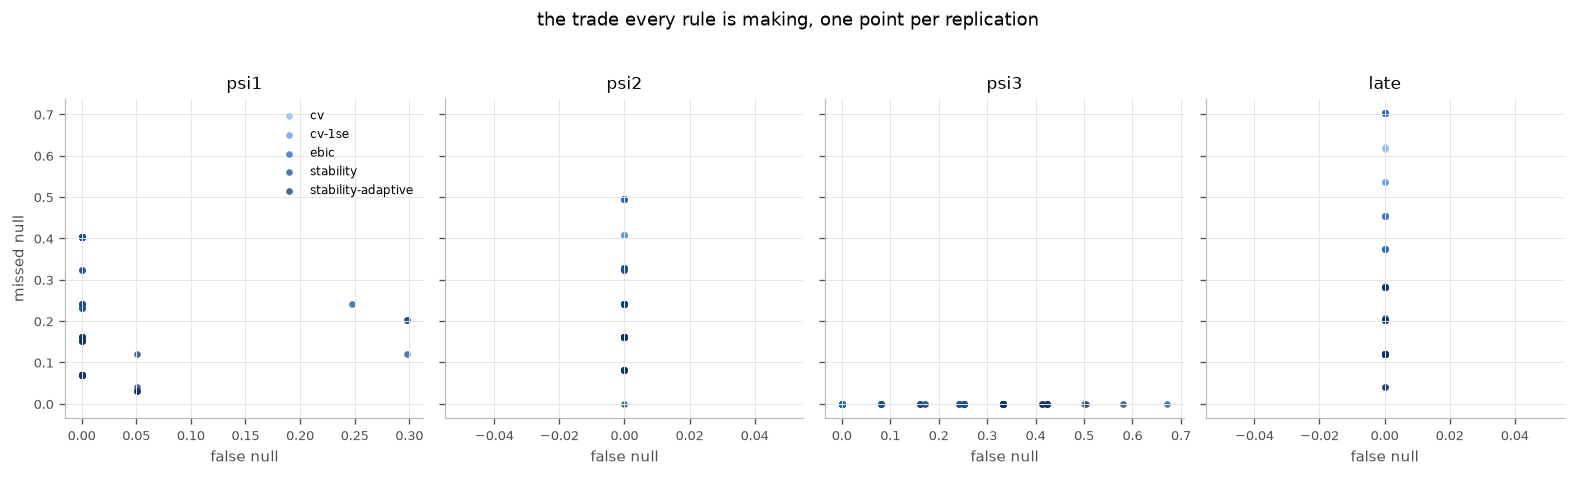

In [9]:
fig, axes = plt.subplots(1, len(designs), figsize=(3.3 * len(designs), 3.8), sharey=True)
for ax, design in zip(np.atleast_1d(axes), designs):
    sub = frame[frame["design"] == design]
    for rule, colour in zip(rules, style.ordinal(len(rules))):
        here = sub[sub["rule"] == rule]
        ax.scatter(here["false_null"], here["missed_null"], s=16, color=colour, alpha=0.75,
                   lw=0, label=rule if design == designs[0] else None)
    ax.set_xlabel("false null"); ax.set_title(design)
np.atleast_1d(axes)[0].set_ylabel("missed null")
np.atleast_1d(axes)[0].legend(frameon=False, fontsize=7, loc="upper right")
fig.suptitle("the trade every rule is making, one point per replication", y=1.03)
fig.tight_layout()

## 5. On real curves: does the method find the New York opening bell?

`notebooks/jump_covariates.ipynb` finds that the London session predicts the sign of the New
York overnight jump, and that **truncating** it at 13:00 London improves the forecast rather
than merely legitimising it -- the London afternoon overlaps the New York session, so it
responds to the move that follows the open instead of predicting it. Thirteen hundred hours is
a convention, though, and the right way to choose a truncation point is not by convention.

This is the test worth running because the answer is known and the method is not told it. The
London session runs 08:00 to 16:00 in these bars, and New York opens at 14:30 or 13:30 London
depending on which side of the daylight-saving mismatch the date falls -- that is $s = 0.81$ or
$s = 0.69$ of the normalised domain. If the certified null region lands past there, the method
has found a structural boundary in 482 nights of prices without being told it exists.

The run is done at two resolutions, because the resolution is not a detail here. The bound is
driven by $\theta = q / n_{\text{groups}}$, so a coarse basis with few groups puts $\theta$
above a half at every size and certifies nothing whatever the data says.

In [10]:
bars = itd.load_bars("1h")
Xl, lgrid, ldates = itd.session_curves(bars[bars["ticker"] == "^FTSE"], kind="ret")
jumps = itd.overnight_jumps(bars[bars["ticker"] == "SPY"])
Xa, ya, when = itd.align_curves_to_series(Xl, ldates, jumps["jump"], offset=0)
ya = np.asarray(ya, float) * 100.0                    # percent, so the penalty is readable

LONDON_BASIS = 35
resolved = {}
for basis in (N_BASIS, LONDON_BASIS):
    c = stability.selection_curves(Xa, ya, lgrid, n_basis=basis, order=ORDER, n_pairs=50,
                                   n_lambda=25, block=5, rng=0)
    resolved[basis] = (c, stability.select(c, pfer=1.0, pner=1.0))
    print(f"{c['n_groups']:>3} knot intervals: theta runs "
          f"{c['q'].min() / c['n_groups']:.2f} to {c['q'].max() / c['n_groups']:.2f}, "
          f"certified {int(resolved[basis][1]['informative'].sum())} informative and "
          f"{int(resolved[basis][1]['null'].sum())} null")

lcurves, lchosen = resolved[LONDON_BASIS]
print()
print(f"{len(ya)} nights, read at {lcurves['n_groups']} knot intervals of width "
      f"{1 / lcurves['n_groups']:.3f}, which is "
      f"{8 * 60 / lcurves['n_groups']:.0f} minutes of the London session")
for name in ("informative", "null", "undecided"):
    spans = [(round(a, 3), round(b, 3)) for a, b in stability.regions(lchosen[name], lcurves)]
    print(f"  {name:<12}: {spans}")
print(f"  bounds: false inclusions <= {lchosen['bound_false']:.3f}, "
      f"false exclusions <= {lchosen['bound_missed']:.3f}")


def london_clock(s):
    """The wall-clock time a point of the normalised domain corresponds to."""
    minutes = 8 * 60 * float(s)
    return f"{8 + int(minutes // 60):02d}:{int(minutes % 60):02d}"


# The sparse base procedure is the one whose proportions have any shape: at the dense size
# every group survives every half-sample, which is why nothing there can be certified null.
above = np.flatnonzero(lchosen["pi_in"] >= 0.5)
crossing = lcurves["edges"][above[-1] + 1] if above.size else np.nan
print()
print("  proportions at the sparse size, one per knot interval:")
print("   ", np.round(lchosen["pi_in"], 2))
print(f"  at the dense size they are {np.round(lchosen['pi_out'].min(), 2)} at their lowest, "
      f"which is why nothing is certified null")
print(f"  the sparse proportions are above a half for the last time on the interval ending at "
      f"s = {crossing:.3f}, which is {london_clock(crossing)} London")
print("  New York opens at 14:30 or 13:30 London, i.e. s = 0.812 or s = 0.688")
for name in ("informative", "null"):
    for lo, hi in stability.regions(lchosen[name], lcurves):
        print(f"  certified {name} [{lo:.3f}, {hi:.3f}] is "
              f"{london_clock(lo)} to {london_clock(hi)} London")

 12 knot intervals: theta runs 0.79 to 1.00, certified 0 informative and 0 null


 32 knot intervals: theta runs 0.46 to 1.00, certified 3 informative and 0 null

482 nights, read at 32 knot intervals of width 0.031, which is 15 minutes of the London session
  informative : [(0.344, 0.438)]
  null        : []
  undecided   : [(0.0, 0.344), (0.438, 1.0)]
  bounds: false inclusions <= 0.964, false exclusions <= 0.000

  proportions at the sparse size, one per knot interval:
    [0.1  0.13 0.28 0.46 0.49 0.5  0.62 0.67 0.67 0.68 0.91 0.93 0.93 0.93
 0.79 0.78 0.76 0.69 0.39 0.4  0.4  0.29 0.29 0.27 0.27 0.26 0.17 0.14
 0.14 0.11 0.07 0.07]
  at the dense size they are 1.0 at their lowest, which is why nothing is certified null
  the sparse proportions are above a half for the last time on the interval ending at s = 0.562, which is 12:30 London
  New York opens at 14:30 or 13:30 London, i.e. s = 0.812 or s = 0.688
  certified informative [0.344, 0.438] is 10:45 to 11:30 London


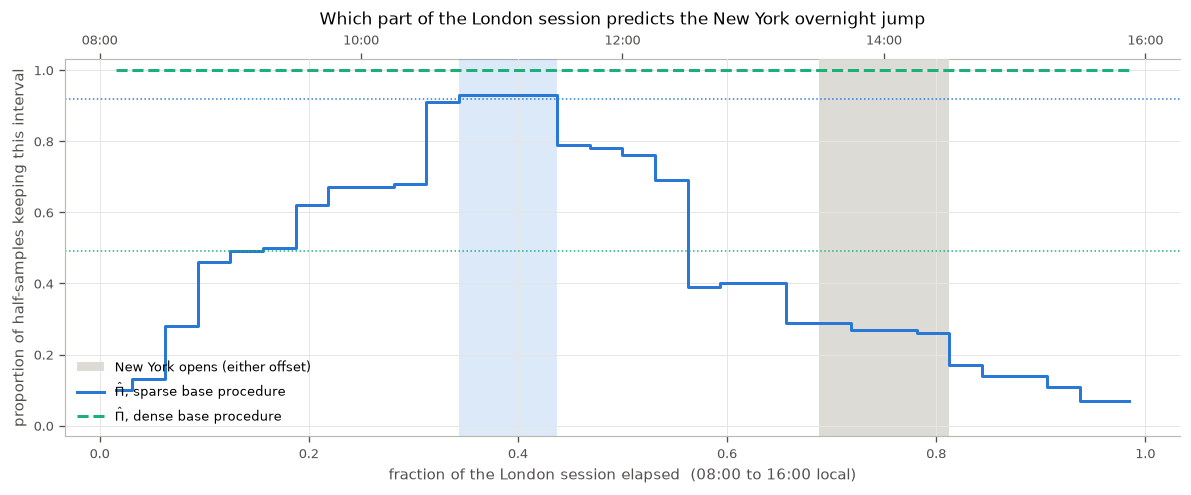

In [11]:
lmid = 0.5 * (lcurves["edges"][:-1] + lcurves["edges"][1:])
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.axvspan(0.6875, 0.8125, color=style.BAND, alpha=0.9, lw=0,
           label="New York opens (either offset)")
for lo, hi in stability.regions(lchosen["informative"], lcurves):
    ax.axvspan(lo, hi, color=INFORMATIVE, alpha=0.16, lw=0)
for lo, hi in stability.regions(lchosen["null"], lcurves):
    ax.axvspan(lo, hi, color=NULL_C, alpha=0.2, lw=0)
ax.step(lmid, lchosen["pi_in"], where="mid", color=INFORMATIVE, lw=1.8,
        label=r"$\hat\Pi$, sparse base procedure")
ax.step(lmid, lchosen["pi_out"], where="mid", color=NULL_C, lw=1.8, ls="--",
        label=r"$\hat\Pi$, dense base procedure")
ax.axhline(lchosen["tau_hi"], color=INFORMATIVE, lw=0.9, ls=":")
ax.axhline(lchosen["tau_lo"], color=NULL_C, lw=0.9, ls=":")
ax.set_xlabel("fraction of the London session elapsed  (08:00 to 16:00 local)")
ax.set_ylabel("proportion of half-samples keeping this interval")
ax.set_title("Which part of the London session predicts the New York overnight jump")
ax.set_ylim(-0.03, 1.03)
ax.legend(frameon=False, loc="lower left", fontsize=8)
secondary = ax.secondary_xaxis("top")
secondary.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
secondary.set_xticklabels(["08:00", "10:00", "12:00", "14:00", "16:00"])
fig.tight_layout()

In [12]:
# What the prediction-targeting rules say about the same curves and the same nights.
lfolds = itd.date_blocked_folds(np.asarray(when), 10)
lpath = SBC.fit_path(Xa, ya, lgrid, n_basis=LONDON_BASIS, order=ORDER, n_lambda=40)
lcv = SBC.cv_fit(Xa, ya, lgrid, lambdas=lpath["lambdas"], n_basis=LONDON_BASIS, order=ORDER,
                 folds=lfolds)
lbest = int(np.argmin(lcv["cv_mean"]))
lone = int(np.argmax(lcv["cv_mean"] <= lcv["cv_mean"][lbest] + lcv["cv_se"][lbest]))
lebic = criteria.ebic(lpath, ya)

for label, step in (("cross-validation", lbest), ("cross-validation, 1 SE", lone),
                    ("EBIC", lebic["step"])):
    regions = SBC.find_regions(~lpath["supports"][step], lgrid)
    print(f"  {label:<24} null set {[(round(a, 3), round(b, 3)) for a, b in regions]}")
print(f"  {'stability, certified':<24} null set "
      f"{[(round(a, 3), round(b, 3)) for a, b in stability.regions(lchosen['null'], lcurves)]}")

  cross-validation         null set []
  cross-validation, 1 SE   null set [(np.float64(0.0), np.float64(1.0))]
  EBIC                     null set [(np.float64(0.0), np.float64(1.0))]
  stability, certified     null set []


## What this notebook found

**Cross-validation's failure to deliver local sparsity is a property of the rule, not of the
estimator.** Over 25 replications of each of four designs, on one shared penalty path, the
cross-validated fit returns a null set of length zero on every replication of `psi1` and of
`psi3`, on 84% of `psi2` and on 68% of `late`. Stability selection returns a non-empty null set
on every replication of every design, and on the two designs where a null set exists and is
found by both, it is the larger and the more accurate one.

**Adaptive weights are what close the gap on the hard design.** On `psi1`, whose informative
region is two pieces at opposite ends of the domain, plain stability selection recovers a
median Jaccard overlap of 0.40 with the true null set and leaves half the domain undecided;
weighting the penalty by a pilot fit raises that to 0.83 and cuts the undecided band to an
eighth. The base procedure is what stability selection inherits, and improving it is worth more
than reading it harder.

**The information criterion is the competitor to beat, not cross-validation.** EBIC matches
stability selection exactly on the right-anchored design, at one path fit against a hundred,
and comes within a third of it on `psi2`. What it does not return is an error bound or an
undecided set, and on this evidence that is the whole of what the extra hundred fits buy.

**On the control, the guarantee holds and the answer is still wrong.** `psi3` has no null
region at all, and stability selection declares part of the domain null on every single
replication -- a quarter of it on average, and a third under adaptive weights. The bound is not
violated: it controls the number of declared-null groups whose *selection probability under the
base procedure* is high, and near $t = 0.5$, where $10(t-0.5)^3$ is under four per cent of its
peak, the base procedure genuinely almost never selects them. That is the honest limit of the
method and it is not a small one. A bound stated relative to a base procedure cannot rescue a
signal that base procedure never finds, and no amount of subsampling turns an undetectable
region into a detected one.

**On the London curve the method needs resolution before it can certify anything.** At 12 knot
intervals the base procedure keeps four fifths of what it is offered at every size, so $\theta$
never falls below 0.78 and nothing is certifiable in either direction, whatever the data says.
That is not a property of the data; it is the arithmetic of the bound, and it says that a
functional penalty has to be read at a fine enough basis for the error control to have any
purchase.

**On real curves the prediction rules collapse to zeroing everything.** Given the same 482
nights, cross-validation returns no null set at all, and both the one-standard-error rule and
EBIC return the *whole domain* -- they zero the coefficient function outright, which is the
same claim as "nothing here predicts the New York open". The certified method, on the same
path, names an interval that does. That is the failure mode this notebook opened with, seen
from the other side: a rule chosen for prediction risk will happily discard a signal too small
to pay for itself in held-out error, and where the question is which part of the domain
matters, that is the wrong trade.

**Read finely enough, the informative half of the claim is certified and the null half is
not.** The selection proportions rise through the London morning, hold near their maximum
across the late morning, and fall away through the early afternoon, and what the method
certifies is an informative interval in that late morning -- the same interval at every
resolution tried. It certifies nothing null at all here, and in a sweep over knot resolution
(`docs/research-log.md`) the null half is either empty or one interval of the coarsest
available width whose position moves with the basis, which is noise rather than a finding.

**What is stable is where the proportions fall away, and it is not the opening bell.** They
hold above a half through the London morning and drop through the early afternoon, well before
either daylight-saving offset puts New York's open. Which is to say the London session stops
carrying information about the New York open *before* New York opens -- the afternoon is not
merely contaminated by the session it is supposed to forecast, it is uninformative for a while
beforehand as well. The 13:00 cutoff that `notebooks/jump_covariates.ipynb` chose by hand, for
feasibility, sits close to that. A per-family error rate of one will not certify it, and the
reason is the arithmetic of the bound rather than the data: `theta` stays above a half over
most of the size profile even at 32 knot intervals, and that is exactly where the substitution
of the candidate count for the number of rarely-selected groups is at its crudest.